# 5G Channel Response under UE Rotation

This notebook explores how user equipment (UE) orientation affects measured 5G channel-state information (CSI). It aligns channel estimates with motion capture poses, identifies five rotation measurement intervals from yaw zero crossings, and reproduces the trajectory, channel magnitude waterfall, and publication figures used in the accompanying study.

The analysis expects one channel estimate pickle per sample and a `position_data.txt` motion log. Configure their location and optional figure export in **Parameters and output settings** below.

## 1. Preparation and data alignment

### Imports

In [1]:
import os
import pickle
from concurrent.futures import FIRST_COMPLETED, ThreadPoolExecutor, wait
from datetime import datetime
from pathlib import Path
from zoneinfo import ZoneInfo

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.collections import LineCollection
from scipy.spatial.transform import Rotation
from tqdm.auto import tqdm

### Parameters and output settings

Set the `CAEZ_5G_DATA_DIR` environment variable to the extracted measurement directory, or edit `DATA_DIR`. `CHANNEL_LOAD_WORKERS` and `CHANNEL_BATCH_SIZE` control bounded parallel loading. To save every generated figure as a publication ready PDF, set `FIGURE_OUTPUT_DIR` to a directory such as `Path("figures")`; leave it as `None` to display figures without writing files.

In [2]:
DATA_DIR = Path(
    os.environ.get("CAEZ_5G_DATA_DIR", "../datasets/rotation_experiment_2026_03_13")
).expanduser()
MOVEMENT_FILE = DATA_DIR / "position_data.txt"
FIGURE_OUTPUT_DIR = Path("figures")
MOVEMENT_TIMEZONE = ZoneInfo("Europe/Zurich")
CHANNEL_TIME_OFFSET_SECONDS = -3600
CHANNEL_LOAD_WORKERS = min(8, os.cpu_count() or 1)
CHANNEL_BATCH_SIZE = 32

N_ORUS = 4
N_RX_ANTENNAS_PER_ORU = 4
N_TX_ANTENNAS = 1
N_PRBS = 273
N_DMRS_SYMBOLS = 3


def save_figure(figure, filename, **savefig_kwargs):
    """Save a figure when figure export is enabled."""
    if FIGURE_OUTPUT_DIR is None:
        return

    output_directory = Path(FIGURE_OUTPUT_DIR)
    output_directory.mkdir(parents=True, exist_ok=True)
    figure.savefig(output_directory / filename, **savefig_kwargs)


def centers_to_edges(values):
    """Convert one-dimensional sample centers to bin edges for `pcolormesh`."""
    values = np.asarray(values)
    if values.size < 2:
        raise ValueError("At least two sample centers are required.")

    edges = np.empty(values.size + 1, dtype=float)
    edges[1:-1] = (values[:-1] + values[1:]) / 2
    edges[0] = values[0] - (values[1] - values[0]) / 2
    edges[-1] = values[-1] + (values[-1] - values[-2]) / 2
    return edges

### Index channel-estimate files

Each trusted pickle contains one complex channel estimate tensor. At this stage, only the sorted paths and timestamps encoded in their filenames are collected. Deferring payload reads until after the plotted measurement intervals are identified allows the notebook to retain only data that a figure uses.

In [3]:
def index_channel_estimate_files(data_directory):
    """Return trusted pickle paths and their filename-encoded timestamps."""
    data_directory = Path(data_directory)
    data_files = sorted(
        path for path in data_directory.glob("*.pickle") if path.is_file()
    )
    if not data_files:
        raise FileNotFoundError(
            f"No channel-estimate pickles found in {data_directory.resolve()}"
        )

    timestamps = np.asarray(
        [float(data_file.name.split("_", maxsplit=1)[0]) for data_file in data_files],
        dtype=np.float64,
    )
    return data_files, timestamps


channel_data_files, channel_timestamps = index_channel_estimate_files(DATA_DIR)
n_samples = len(channel_data_files)
print(f"Indexed {n_samples} channel-estimate files in {DATA_DIR}")

Indexed 132981 channel-estimate files in ../datasets/rotation_experiment_2026_03_13


### Load motion capture data

Each motion log row supplies a local timestamp, Cartesian position, and quaternion. Timestamp strings and numeric poses are parsed in contiguous arrays, and all quaternions are converted to the experiment's `zxy` Euler angle convention in one vectorized SciPy call.

In [4]:
def parse_local_timestamps(datetime_texts, timezone):
    """Vectorize fixed-format local timestamps into Unix seconds."""
    first_datetime = datetime.fromisoformat(datetime_texts[0]).replace(tzinfo=timezone)
    first_offset = first_datetime.utcoffset()

    local_microseconds = np.asarray(datetime_texts, dtype="datetime64[us]").astype(
        np.int64
    )
    return local_microseconds / 1_000_000 - first_offset.total_seconds()


def load_movement_data(movement_file, timezone):
    """Load positions and vectorized `zxy` Euler angles from the motion log."""
    movement_file = Path(movement_file)
    if not movement_file.is_file():
        raise FileNotFoundError(f"Motion-capture log not found: {movement_file.resolve()}")

    datetime_texts = []
    pose_rows = []
    with movement_file.open("r", encoding="utf-8") as file_handle:
        for line_number, line in enumerate(file_handle, start=1):
            line = line.strip()
            if not line:
                continue

            try:
                datetime_text, pose_text = line.rsplit(" ", 1)
                position_text, quaternion_text = pose_text.split(";")
                if len(position_text.split(",")) != 3:
                    raise ValueError("expected three position values")
                quaternion_text = quaternion_text.removesuffix(",")
                if len(quaternion_text.split(",")) != 4:
                    raise ValueError("expected four quaternion values")
            except ValueError as error:
                print(f"Skipping malformed motion row {line_number}: {error}")
                continue

            datetime_texts.append(datetime_text)
            pose_rows.append(f"{position_text},{quaternion_text}")

    if not datetime_texts:
        raise ValueError(f"No valid motion samples found in {movement_file}")

    pose_values = np.fromstring(",".join(pose_rows), sep=",")
    expected_values = len(pose_rows) * 7
    if pose_values.size != expected_values:
        raise ValueError(
            f"Parsed {pose_values.size} motion values; expected {expected_values}."
        )
    pose_values = pose_values.reshape(-1, 7)

    positions = pose_values[:, :3]
    quaternions = pose_values[:, 3:]
    rotations = Rotation.from_quat(quaternions).as_euler("zxy", degrees=True)
    movement_timestamps = parse_local_timestamps(datetime_texts, timezone)
    return positions, rotations, movement_timestamps


movement_positions_raw, movement_rotations_raw, movement_timestamps_raw = load_movement_data(
    MOVEMENT_FILE, MOVEMENT_TIMEZONE
)

### Align timestamp conventions

The channel filenames use the acquisition system's local clock. The fixed one hour offset used during the experiment converts those values to the same UTC basis as the timezone aware motion timestamps.

In [5]:
channel_timestamps = channel_timestamps + CHANNEL_TIME_OFFSET_SECONDS

### Match channel samples to the nearest pose

The motion timestamps are sorted, so `searchsorted` finds the nearest pose for every channel sample without constructing a large pairwise difference matrix. Equal distance ties select the earlier pose, matching `argmin` behavior.

In [6]:
def match_channel_and_movement_data(
    channel_timestamps, movement_timestamps, movement_positions, movement_rotations
):
    """Associate each channel sample with its nearest motion sample."""
    if movement_timestamps.size == 0:
        raise ValueError("Movement timestamps must not be empty.")
    if np.any(np.diff(movement_timestamps) < 0):
        raise ValueError("Movement timestamps must be sorted in ascending order.")

    right_indices = np.searchsorted(movement_timestamps, channel_timestamps, side="left")
    right_indices = np.clip(right_indices, 0, movement_timestamps.size - 1)
    left_indices = np.maximum(right_indices - 1, 0)

    left_distances = np.abs(channel_timestamps - movement_timestamps[left_indices])
    right_distances = np.abs(movement_timestamps[right_indices] - channel_timestamps)
    nearest_indices = np.where(right_distances < left_distances, right_indices, left_indices)
    # For duplicate timestamps, select their first occurrence as `np.argmin` does.
    nearest_indices = np.searchsorted(
        movement_timestamps, movement_timestamps[nearest_indices], side="left"
    )

    return (
        movement_positions[nearest_indices].astype(np.float32, copy=False),
        movement_rotations[nearest_indices].astype(np.float32, copy=False),
    )


positions_in_channel_time, rotations_in_channel_time = match_channel_and_movement_data(
    channel_timestamps,
    movement_timestamps_raw,
    movement_positions_raw,
    movement_rotations_raw,
)

### Identify the measurement intervals

Yaw sign changes mark half rotation boundaries. Discontinuities of 180° or more are excluded as angle wrap around rather than true zero crossings. The crossing indices are calculated once and reused by the interval selection and publication plots. The selected pairs below delimit the five complete five rotation acquisitions used by the subsequent plots.

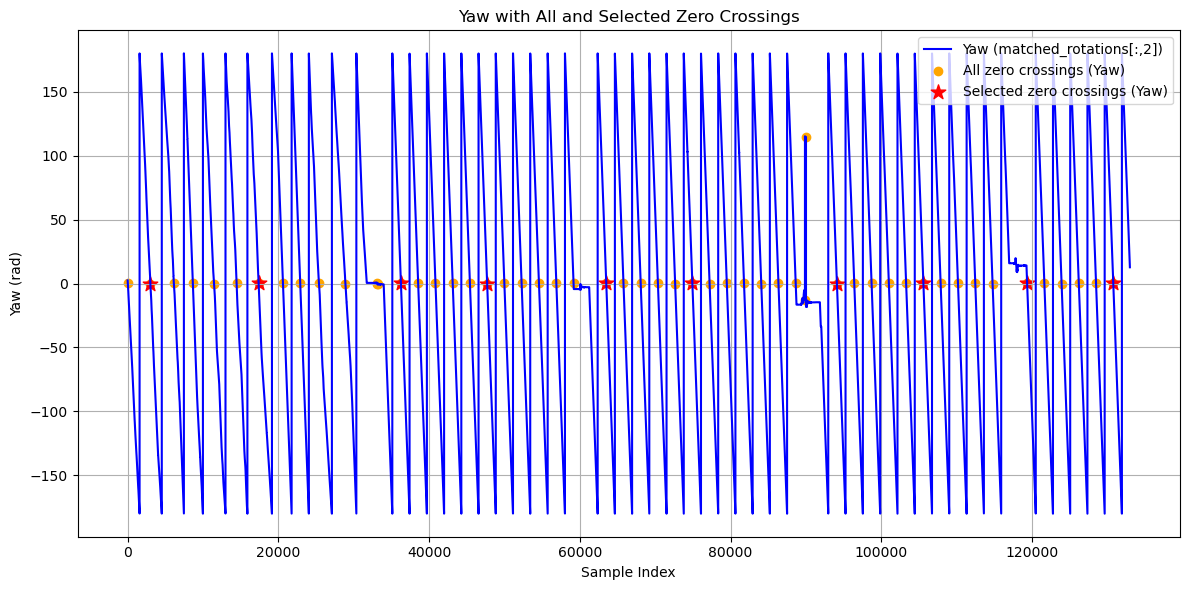

In [7]:
def calculate_yaw_zero_crossings(rotations_in_channel_time):
    """Return yaw zero crossings while excluding ±180° wrap-around jumps."""
    signal = rotations_in_channel_time[:, 2]
    sign_change_indices = np.where(np.diff(np.signbit(signal)))[0]
    angular_steps = np.abs(np.diff(signal))
    non_wrap_mask = angular_steps[sign_change_indices] < 180.0
    return sign_change_indices[non_wrap_mask]


def extract_measurement_intervals(
    rotations_in_channel_time, zero_crossings_yaw, plot=True
):
    """Select the five experiment intervals from cached yaw zero crossings."""
    
    # Hardcoded selection of zero crossings using numpy
    selected_zero_crossings = np.array([(1, 6), (14, 19), (25, 30), (39, 44), (49, 54)])
    selection_indices = selected_zero_crossings.flatten()
    selection_indices = selection_indices[(selection_indices >= 0) & (selection_indices < len(zero_crossings_yaw))]
    measurement_intervals = zero_crossings_yaw[selection_indices]

    if plot:
        # Plot matched_rotations[:,2] (yaw), all zero crossings, and selected zero crossings
        figure = plt.figure(figsize=(12, 6))
        plt.plot(rotations_in_channel_time[:, 2], label="Yaw (matched_rotations[:,2])", color='b')
        plt.scatter(zero_crossings_yaw, rotations_in_channel_time[zero_crossings_yaw, 2], color="orange", marker="o", label="All zero crossings (Yaw)")
        if measurement_intervals.size > 0:
            plt.scatter(measurement_intervals, rotations_in_channel_time[measurement_intervals, 2], color="red", marker="*", s=120, label="Selected zero crossings (Yaw)")
        plt.xlabel("Sample Index")
        plt.ylabel("Yaw (rad)")
        plt.title("Yaw with All and Selected Zero Crossings")
        plt.legend()
        plt.grid(True)
        plt.tight_layout()
        
        save_figure(figure, "measurement_intervals_from_yaw_zero_crossings.pdf")

    return measurement_intervals.reshape(-1, 2)

zero_crossings_yaw = calculate_yaw_zero_crossings(rotations_in_channel_time)
measurement_intervals = extract_measurement_intervals(
    rotations_in_channel_time, zero_crossings_yaw
)

### Reference channel time to acquisition start

Subtracting the first channel timestamp produces elapsed seconds while retaining the original sampling intervals.

In [8]:
channel_timestamps_from_0 = channel_timestamps - channel_timestamps[0]

## 2. Movement trajectory

The first diagnostic plot shows the UE path in the horizontal x–z plane. Color encodes sample order, making the direction of travel visible without changing the trajectory geometry.

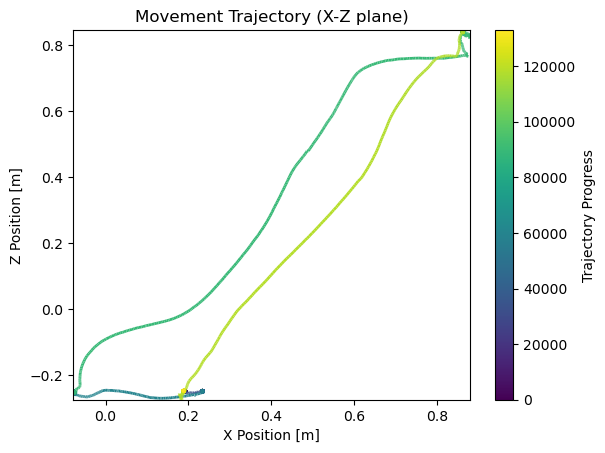

In [9]:
def plot_movement_trajectory(positions_in_channel_time):
    """
    Plots the movement trajectory in x-z plane with a line color gradient.
    """
    if positions_in_channel_time is None or len(positions_in_channel_time) == 0:
        print("No positions data to plot.")
        return

    x = positions_in_channel_time[:, 0]
    z = positions_in_channel_time[:, 2]

    # Create segments for LineCollection
    points = np.array([x, z]).T.reshape(-1, 1, 2)
    segments = np.concatenate([points[:-1], points[1:]], axis=1)

    # Create the color gradient
    norm = plt.Normalize(0, len(x) - 1)
    lc = LineCollection(segments, cmap='viridis', norm=norm)
    lc.set_array(np.arange(len(x) - 1))
    lc.set_linewidth(2)

    fig, ax = plt.subplots()
    line = ax.add_collection(lc)
    fig.colorbar(line, ax=ax, label='Trajectory Progress')
    ax.set_xlim(x.min(), x.max())
    ax.set_ylim(z.min(), z.max())
    ax.set_xlabel('X Position [m]')
    ax.set_ylabel('Z Position [m]')
    ax.set_title('Movement Trajectory (X-Z plane)')

    save_figure(fig, "ue_movement_trajectory_xz_plane.pdf")

plot_movement_trajectory(positions_in_channel_time)

## 3. Normalized channel magnitudes

### Stream, average, and normalize the channel estimates

Pickles are processed in bounded parallel batches. For each sample, the complex tensor is converted to `complex64`, its magnitude is averaged over the singleton transmit antenna axis and three DMRS symbols, and each O-RU is immediately normalized by the Frobenius norm across receive antennas and subcarriers. Only antenna 0 within the plotted measurement intervals is retained. The raw sample and all other normalized values are then discarded. Per-O-RU/antenna and global extrema are still accumulated across every sample once for color scales of the figures.

In [10]:
def _process_channel_batch(
    start_index,
    data_files,
    sample_shape,
    retained_sample_mask,
    retained_antenna_indices,
):
    """Normalize one file batch and return only figure-relevant samples."""
    n_orus, n_rx_antennas, _, n_subcarriers, _ = sample_shape
    batch_minima = np.full((n_orus, n_rx_antennas), np.inf, dtype=np.float32)
    batch_maxima = np.full((n_orus, n_rx_antennas), -np.inf, dtype=np.float32)
    retained_global_indices = []
    retained_magnitudes = []

    for batch_offset, data_file in enumerate(data_files):
        global_index = start_index + batch_offset
        with data_file.open("rb") as file_handle:
            sample = pickle.load(file_handle)

        channel_estimate = np.squeeze(
            np.asarray(sample["ch_est"], dtype=np.complex64), axis=1
        )
        del sample
        if channel_estimate.shape != sample_shape:
            raise ValueError(
                f"Unexpected channel shape {channel_estimate.shape} in {data_file}; "
                f"expected {sample_shape}."
            )

        magnitudes = np.mean(np.abs(channel_estimate), axis=(2, 4))
        normalization = np.linalg.norm(
            magnitudes, ord="fro", axis=(1, 2), keepdims=True
        )
        if np.any(normalization == 0):
            raise ValueError(
                f"Cannot normalize the zero-magnitude channel sample in {data_file}."
            )
        normalized_magnitudes = magnitudes / normalization

        batch_minima = np.minimum(
            batch_minima, np.min(normalized_magnitudes, axis=2)
        )
        batch_maxima = np.maximum(
            batch_maxima, np.max(normalized_magnitudes, axis=2)
        )
        if retained_sample_mask[global_index]:
            retained_global_indices.append(global_index)
            retained_magnitudes.append(
                normalized_magnitudes[:, retained_antenna_indices, :].copy()
            )

        # Release the raw tensor before decoding the next pickle.
        del channel_estimate, magnitudes, normalization, normalized_magnitudes

    if retained_magnitudes:
        retained_magnitudes = np.stack(retained_magnitudes)
    else:
        retained_magnitudes = np.empty(
            (0, n_orus, len(retained_antenna_indices), n_subcarriers),
            dtype=np.float32,
        )

    return (
        len(data_files),
        np.asarray(retained_global_indices, dtype=np.int64),
        retained_magnitudes,
        batch_minima,
        batch_maxima,
    )


def _iter_parallel_processed_batches(batches, worker_arguments, max_workers):
    """Yield processed batches while bounding queued work and memory use."""
    batch_iterator = iter(batches)
    with ThreadPoolExecutor(max_workers=max_workers) as executor:
        pending = set()
        for _ in range(2 * max_workers):
            try:
                start_index, data_files = next(batch_iterator)
            except StopIteration:
                break
            pending.add(
                executor.submit(
                    _process_channel_batch,
                    start_index,
                    data_files,
                    *worker_arguments,
                )
            )

        while pending:
            completed, pending = wait(pending, return_when=FIRST_COMPLETED)
            for future in completed:
                yield future.result()
                try:
                    start_index, data_files = next(batch_iterator)
                except StopIteration:
                    continue
                pending.add(
                    executor.submit(
                        _process_channel_batch,
                        start_index,
                        data_files,
                        *worker_arguments,
                    )
                )


def stream_normalized_channel_magnitudes(
    data_files,
    measurement_intervals,
    retained_antenna_indices,
    n_orus,
    n_rx_antennas_per_oru,
    n_tx_antennas,
    n_prbs,
    n_dmrs_symbols,
    n_workers,
    batch_size,
):
    """Stream all pickles while retaining only values consumed by figures."""
    if n_workers < 1 or batch_size < 1:
        raise ValueError("n_workers and batch_size must both be positive.")

    n_samples = len(data_files)
    retained_sample_mask = np.zeros(n_samples, dtype=bool)
    for start_index, end_index in np.asarray(measurement_intervals, dtype=np.int64):
        if not 0 <= start_index < end_index <= n_samples:
            raise ValueError(
                f"Invalid measurement interval [{start_index}, {end_index})."
            )
        retained_sample_mask[start_index:end_index] = True

    retained_sample_indices = np.flatnonzero(retained_sample_mask)
    retained_index_lookup = np.full(n_samples, -1, dtype=np.int64)
    retained_index_lookup[retained_sample_indices] = np.arange(
        retained_sample_indices.size
    )

    retained_antenna_indices = np.asarray(
        retained_antenna_indices, dtype=np.int64
    )
    if (
        retained_antenna_indices.size == 0
        or np.unique(retained_antenna_indices).size != retained_antenna_indices.size
        or np.any(retained_antenna_indices < 0)
        or np.any(retained_antenna_indices >= n_rx_antennas_per_oru)
    ):
        raise ValueError("Retained antenna indices must be unique and in range.")

    sample_shape = (
        n_orus,
        n_rx_antennas_per_oru,
        n_tx_antennas,
        n_prbs * 12,
        n_dmrs_symbols,
    )
    retained_channel_magnitudes = np.empty(
        (
            retained_sample_indices.size,
            n_orus,
            retained_antenna_indices.size,
            n_prbs * 12,
        ),
        dtype=np.float32,
    )
    retained_samples_written = np.zeros(retained_sample_indices.size, dtype=bool)
    minima_by_oru_antenna = np.full(
        (n_orus, n_rx_antennas_per_oru), np.inf, dtype=np.float32
    )
    maxima_by_oru_antenna = np.full(
        (n_orus, n_rx_antennas_per_oru), -np.inf, dtype=np.float32
    )

    n_batches = (n_samples + batch_size - 1) // batch_size
    max_workers = min(n_workers, n_batches)
    batches = (
        (start_index, data_files[start_index : start_index + batch_size])
        for start_index in range(0, n_samples, batch_size)
    )
    worker_arguments = (
        sample_shape,
        retained_sample_mask,
        retained_antenna_indices,
    )
    print(
        f"Streaming {n_samples} channel estimates with {max_workers} workers; "
        f"retaining {retained_sample_indices.size} samples for antennas "
        f"{retained_antenna_indices.tolist()}"
    )

    batch_results = _iter_parallel_processed_batches(
        batches, worker_arguments, max_workers
    )
    with tqdm(total=n_samples, desc="Channel estimates") as progress:
        for (
            processed_sample_count,
            batch_retained_indices,
            batch_retained_magnitudes,
            batch_minima,
            batch_maxima,
        ) in batch_results:
            retained_positions = retained_index_lookup[batch_retained_indices]
            retained_channel_magnitudes[retained_positions] = (
                batch_retained_magnitudes
            )
            retained_samples_written[retained_positions] = True
            minima_by_oru_antenna = np.minimum(
                minima_by_oru_antenna, batch_minima
            )
            maxima_by_oru_antenna = np.maximum(
                maxima_by_oru_antenna, batch_maxima
            )
            progress.update(processed_sample_count)

    if not np.all(retained_samples_written):
        raise RuntimeError("Not every retained channel sample was processed.")

    global_limits = (
        np.min(minima_by_oru_antenna),
        np.max(maxima_by_oru_antenna),
    )
    return (
        retained_channel_magnitudes,
        retained_index_lookup,
        retained_antenna_indices,
        minima_by_oru_antenna,
        maxima_by_oru_antenna,
        global_limits,
    )


def retained_interval_slice(start_index, end_index, retained_index_lookup):
    """Map a complete original interval to its compact storage slice."""
    retained_positions = retained_index_lookup[start_index:end_index]
    if (
        retained_positions.size != end_index - start_index
        or np.any(retained_positions < 0)
        or np.any(np.diff(retained_positions) != 1)
    ):
        raise ValueError("The requested interval was not retained contiguously.")
    return slice(int(retained_positions[0]), int(retained_positions[-1]) + 1)


def retained_antenna_position(antenna_index, retained_antenna_indices):
    """Map an original antenna index to its compact storage position."""
    matches = np.flatnonzero(retained_antenna_indices == antenna_index)
    if matches.size != 1:
        raise ValueError(f"Antenna {antenna_index} was not retained.")
    return int(matches[0])


PLOTTED_ANTENNA_INDICES = (0,)
(
    retained_channel_magnitudes,
    retained_index_lookup,
    retained_antenna_indices,
    channel_magnitude_minima_by_oru_antenna,
    channel_magnitude_maxima_by_oru_antenna,
    global_channel_magnitude_limits,
) = stream_normalized_channel_magnitudes(
    channel_data_files,
    measurement_intervals,
    PLOTTED_ANTENNA_INDICES,
    N_ORUS,
    N_RX_ANTENNAS_PER_ORU,
    N_TX_ANTENNAS,
    N_PRBS,
    N_DMRS_SYMBOLS,
    CHANNEL_LOAD_WORKERS,
    CHANNEL_BATCH_SIZE,
)

Streaming 132981 channel estimates with 8 workers; retaining 60134 samples for antennas [0]


Channel estimates:   0%|          | 0/132981 [00:00<?, ?it/s]

### Channel magnitude waterfalls over time

The first waterfall compares all five measurement intervals for one O-RU/antenna pair using a shared color scale. The second holds the measurement interval fixed and compares the first antenna from each O-RU, again with one global scale. Both receive the cached extrema calculated during preprocessing rather than scanning the channel tensor again.

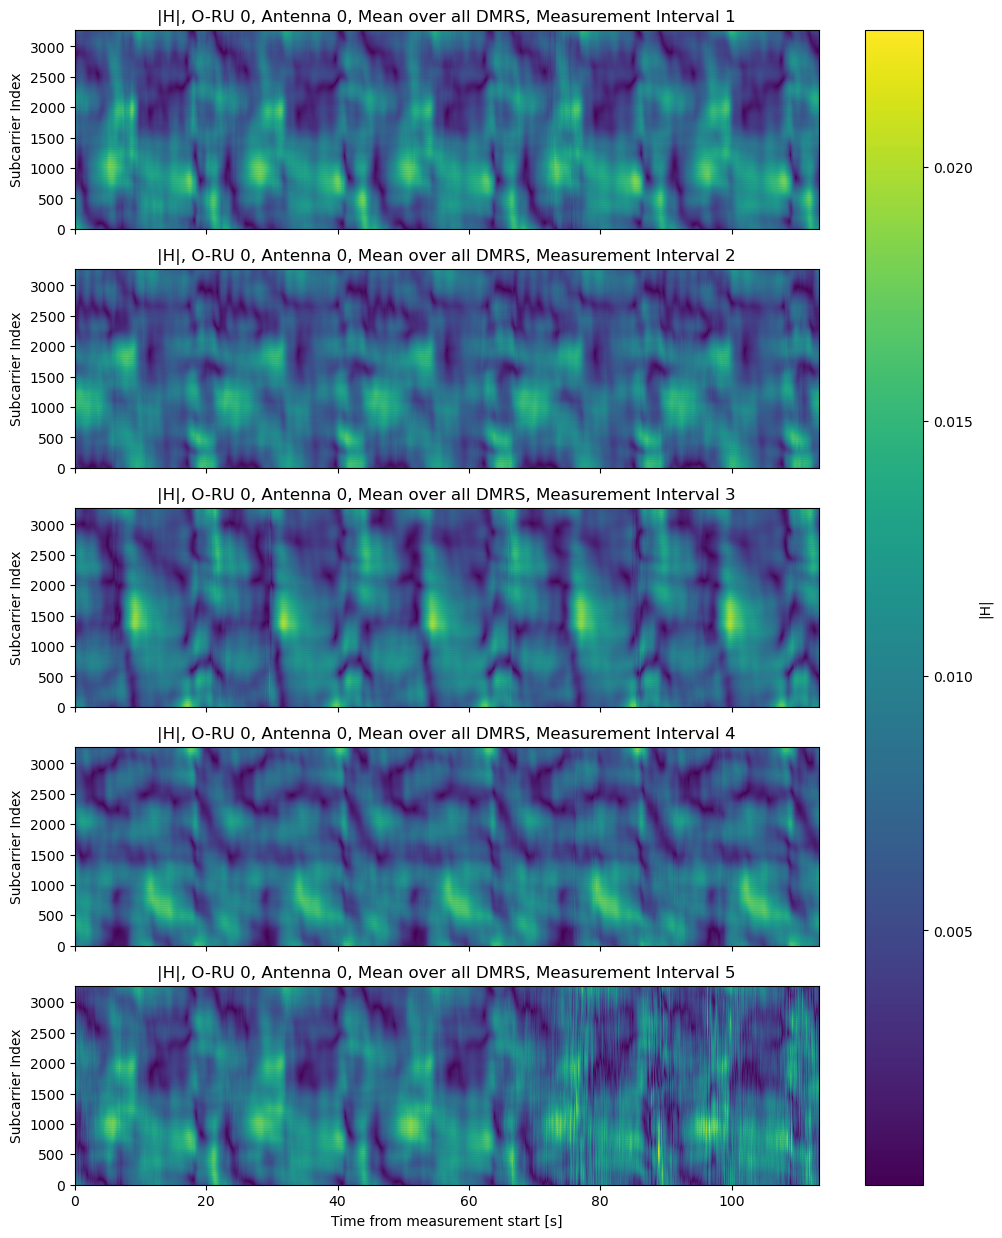

In [11]:
def plot_waterfall_H_vs_time(
    retained_channel_magnitudes,
    measurement_intervals,
    retained_index_lookup,
    retained_antenna_indices,
    elapsed_channel_time,
    n_prbs,
    oru_idx,
    antenna_idx,
    color_limits,
):
    """Plot one O-RU/antenna pair for every selected measurement interval."""
    n_intervals = len(measurement_intervals)
    fig, axs = plt.subplots(n_intervals, 1, figsize=(12, 3 * n_intervals), sharex=True)

    global_vmin, global_vmax = color_limits
    antenna_position = retained_antenna_position(
        antenna_idx, retained_antenna_indices
    )

    ims = []
    for idx, (start_idx, end_idx) in enumerate(measurement_intervals):
        interval_times_from_0 = elapsed_channel_time[start_idx:end_idx] - elapsed_channel_time[start_idx]
        interval_edges = centers_to_edges(interval_times_from_0)

        retained_slice = retained_interval_slice(
            start_idx, end_idx, retained_index_lookup
        )
        h_matrix = retained_channel_magnitudes[
            retained_slice, oru_idx, antenna_position, :
        ].T
        ax = axs[idx] if n_intervals > 1 else axs
        im = ax.pcolormesh(
            interval_edges,
            np.arange(n_prbs * 12 + 1),
            h_matrix,
            vmin=global_vmin,
            vmax=global_vmax,
            rasterized=True,
        )
        ims.append(im)
        ax.set_ylabel('Subcarrier Index')
        ax.set_title(f'|H|, O-RU {oru_idx}, Antenna {antenna_idx}, Mean over all DMRS, Measurement Interval {idx+1}')
        if idx == n_intervals - 1:
            ax.set_xlabel('Time from measurement start [s]')

    # Add a colorbar to the right that is shared across all subplots
    fig.colorbar(ims[0], ax=axs, orientation='vertical', label='|H|')
    save_figure(
        fig,
        f"channel_magnitude_waterfall_all_measurements_oru_{oru_idx}_antenna_{antenna_idx}.pdf",
        dpi=300,
    )


plot_waterfall_H_vs_time(
    retained_channel_magnitudes,
    measurement_intervals,
    retained_index_lookup,
    retained_antenna_indices,
    channel_timestamps_from_0,
    N_PRBS,
    0,
    0,
    (
        channel_magnitude_minima_by_oru_antenna[0, 0],
        channel_magnitude_maxima_by_oru_antenna[0, 0],
    ),
)

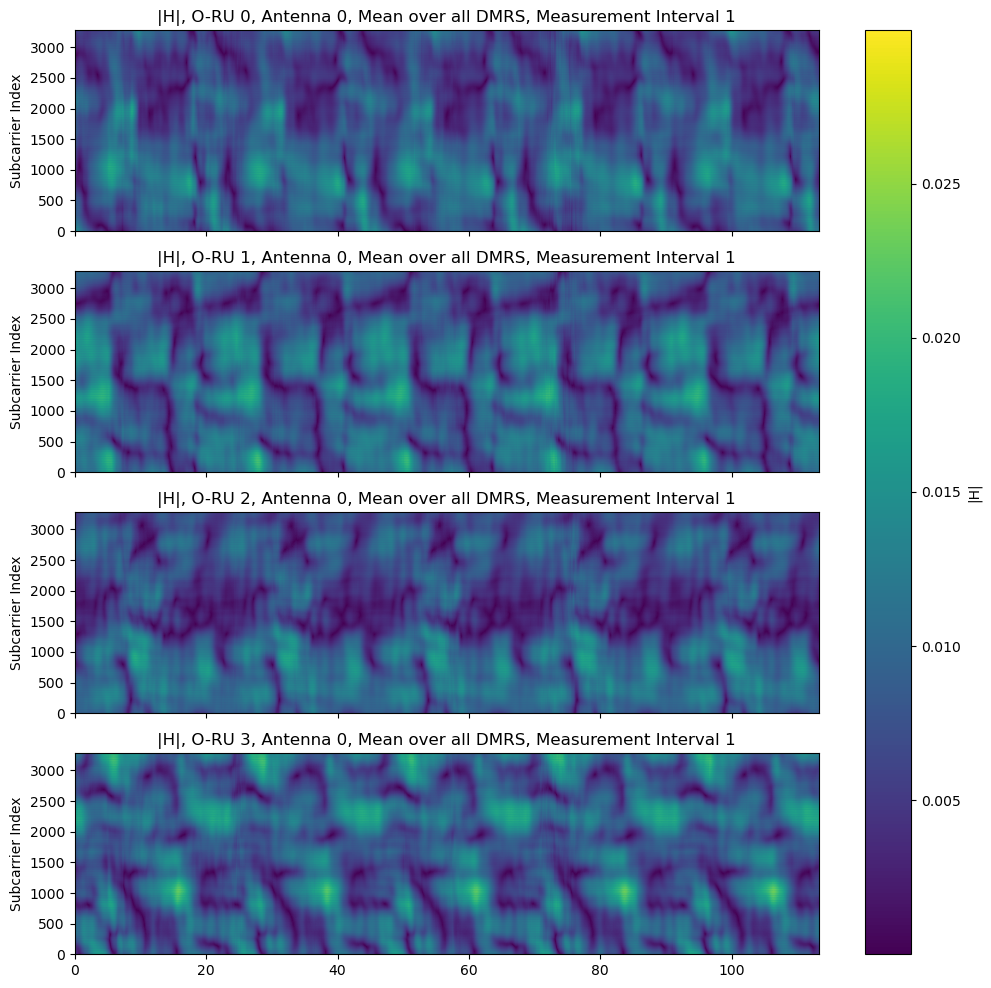

In [12]:
def plot_waterfall_impulse_response_for_different_antennas_vs_time(
    retained_channel_magnitudes,
    measurement_intervals,
    retained_index_lookup,
    retained_antenna_indices,
    elapsed_channel_time,
    n_prbs,
    oru_antenna_pairs,
    measurement_idx,
    color_limits,
):
    """Compare selected O-RU/antenna pairs within one measurement interval."""
    n_intervals = len(measurement_intervals)
    fig, axs = plt.subplots(len(oru_antenna_pairs), 1, figsize=(12, 3 * len(oru_antenna_pairs)), sharex=True)

    global_vmin, global_vmax = color_limits

    ims = []

    measurement_interval = measurement_intervals[measurement_idx]
    start_idx, end_idx = measurement_interval
    retained_slice = retained_interval_slice(
        start_idx, end_idx, retained_index_lookup
    )

    interval_times_from_0 = elapsed_channel_time[start_idx:end_idx] - elapsed_channel_time[start_idx]
    interval_edges = centers_to_edges(interval_times_from_0)

    for idx, (oru_idx, antenna_idx) in enumerate(oru_antenna_pairs):
        antenna_position = retained_antenna_position(
            antenna_idx, retained_antenna_indices
        )
        h_matrix = retained_channel_magnitudes[
            retained_slice, oru_idx, antenna_position, :
        ].T
        ax = axs[idx] if n_intervals > 1 else axs
        im = ax.pcolormesh(
            interval_edges,
            np.arange(n_prbs * 12 + 1),
            h_matrix,
            vmin=global_vmin,
            vmax=global_vmax,
            rasterized=True,
        )
        ims.append(im)
        ax.set_ylabel('Subcarrier Index')
        ax.set_title(f'|H|, O-RU {oru_idx}, Antenna {antenna_idx}, Mean over all DMRS, Measurement Interval {measurement_idx + 1}')
        if idx == n_intervals - 1:
            ax.set_xlabel('Time from measurement start [s]')

    # Add a colorbar to the right that is shared across all subplots
    fig.colorbar(ims[0], ax=axs, orientation='vertical', label='|H|')
    save_figure(
        fig,
        f"channel_magnitude_waterfall_measurement_{measurement_idx}_selected_oru_antennas.pdf",
        dpi=300,
    )


oru_antenna_pairs = [(0, 0), (1, 0), (2, 0), (3, 0)]

plot_waterfall_impulse_response_for_different_antennas_vs_time(
    retained_channel_magnitudes,
    measurement_intervals,
    retained_index_lookup,
    retained_antenna_indices,
    channel_timestamps_from_0,
    N_PRBS,
    oru_antenna_pairs,
    0,
    global_channel_magnitude_limits,
)

## 4. Publication figures

The following figures reproduce the paper-specific comparison.

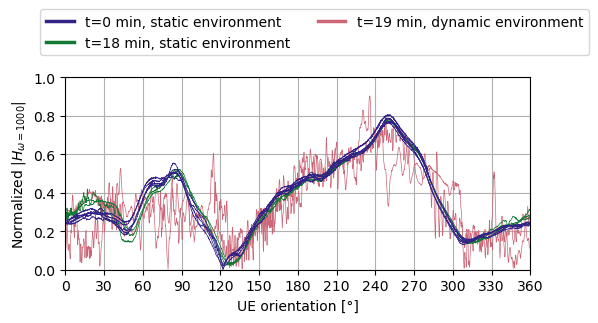

In [13]:
def plot_channel_magnitudes_for_paper(
    retained_channel_magnitudes,
    retained_index_lookup,
    retained_antenna_indices,
    rotations_in_channel_time,
    zero_crossings_yaw,
):
    """Reproduce the paper's normalized magnitude-versus-orientation panel."""
    selected_zero_crossings = np.array([(1, 6), (49, 54)])

    # Collect all zero crossings from selected intervals including the boundary and in-between (internal) crossings
    measurement_all_sub_intervals = []
    for (start, end) in selected_zero_crossings:
        sub_crossings = range(start, end + 1)
        measurement_subintervals = zero_crossings_yaw[sub_crossings]
        measurement_all_sub_intervals.extend(measurement_subintervals)
    measurement_all_sub_intervals = np.array(measurement_all_sub_intervals)

    measurement_all_sub_intervals = measurement_all_sub_intervals.reshape(-1, 6)

    oru_index = 3
    antenna_index = 0
    antenna_position = retained_antenna_position(
        antenna_index, retained_antenna_indices
    )
    subcarrier_index = 1001
    fig, axs = plt.subplots(1, 1, figsize=(6, 2.5), sharex=True)

    colors = ["#332288", "#117733", "#CC6677"]  # indigo, muted green, rose
    min_h = 1.3182255315768998e-05
    max_h = 0.0278985183686018
    wrap_threshold = 180

    for idx, sub_intervals in enumerate(measurement_all_sub_intervals[::-1]):
        for idx_pair, (start, end) in enumerate(zip((sub_intervals[:-1])[::-1], (sub_intervals[1:])[::-1])):
            interval_yaw = (-rotations_in_channel_time[start:end, 2]) % 360

            retained_slice = retained_interval_slice(
                start, end, retained_index_lookup
            )
            h_values = retained_channel_magnitudes[
                retained_slice, oru_index, antenna_position, subcarrier_index
            ]
            h_values_normalized = (h_values - min_h) / (max_h - min_h)

            # Detect wrap jumps
            dx = np.abs(np.diff(interval_yaw))

            # Insert NaNs where jump is too large
            x_plot = interval_yaw.astype(float).copy()
            y_plot = h_values_normalized.astype(float).copy()

            wrap_idxs = np.where(dx > wrap_threshold)[0]

            for wrap_idx in wrap_idxs:
                x_plot = np.insert(x_plot, wrap_idx + 1, np.nan)
                y_plot = np.insert(y_plot, wrap_idx + 1, np.nan)

            if idx == 1:
                if idx_pair == 0:
                    axs.plot(x_plot, y_plot, color=colors[0], linewidth=0.5, label='t=0 min, static environment')
                else:
                    axs.plot(x_plot, y_plot, color=colors[0], linewidth=0.5, label='_nolegend_')
            else:
                if idx_pair == 4:
                    axs.plot(x_plot, y_plot, color=colors[1], linewidth=0.5, label='t=18 min, static environment')
                if idx_pair == 3 or idx_pair == 2:
                    axs.plot(x_plot, y_plot, color=colors[1], linewidth=0.5, label='_nolegend_')
                if idx_pair == 1:
                    axs.plot(x_plot, y_plot, color=colors[2], linewidth=0.5, label='t=19 min, dynamic environment')
                if idx_pair == 0:
                    axs.plot(x_plot, y_plot, color=colors[2], linewidth=0.5, label='_nolegend_')

    axs.set_ylabel(r'Normalized $|H_{\omega=1000}|$')
    # Set x-ticks as the original timestamps for correct labeling
    axs.set_xticks([0, 30, 60, 90, 120, 150, 180, 210, 240, 270, 300, 330, 360])
    axs.set_xticklabels([0, 30, 60, 90, 120, 150, 180, 210, 240, 270, 300, 330, 360])
    axs.set_xlim(0, 360)
    axs.set_ylim(0, 1.0)
    axs.grid(True)

    handles, labels = axs.get_legend_handles_labels()

    legend = fig.legend(handles[::-1], labels[::-1], loc='upper center', ncol=2, bbox_to_anchor=(0.54, 1.18))

    for line in legend.get_lines():
        line.set_linewidth(2.5)
    axs.set_xlabel('UE orientation [°]')
    save_figure(
        fig,
        "normalized_channel_magnitude_vs_ue_orientation.pdf",
        bbox_inches="tight",
        pad_inches=0.1,
    )


plot_channel_magnitudes_for_paper(
    retained_channel_magnitudes,
    retained_index_lookup,
    retained_antenna_indices,
    rotations_in_channel_time,
    zero_crossings_yaw,
)

### Orientation subcarrier waterfall

This panel shows the normalized magnitude across every subcarrier during measurement 5 for O-RU 3 and antenna 0. The dashed line marks 1080° (three complete turns).

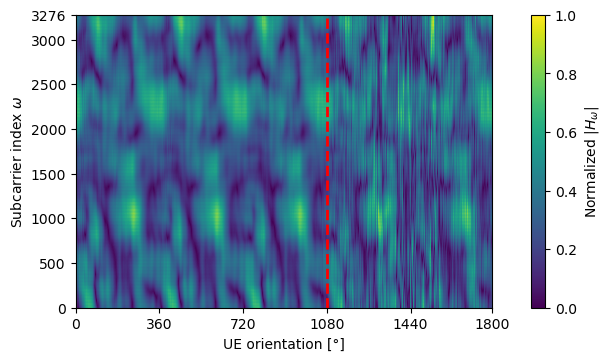

In [14]:
def plot_waterfall_for_paper(
    retained_channel_magnitudes,
    measurement_intervals,
    retained_index_lookup,
    retained_antenna_indices,
    n_prbs,
    rotations_in_channel_time,
):
    """Plot the paper's orientation-by-subcarrier channel-magnitude waterfall."""
    oru_idx = 3
    antenna_idx = 0
    antenna_position = retained_antenna_position(
        antenna_idx, retained_antenna_indices
    )
    
    measurement_idx = 4

    measurement_interval = measurement_intervals[measurement_idx]
    start_idx, end_idx = measurement_interval
    retained_slice = retained_interval_slice(
        start_idx, end_idx, retained_index_lookup
    )
    fig, ax = plt.subplots(1, 1, figsize=(6, 3.5), sharex=True, layout="constrained")

    yaw_values = rotations_in_channel_time[start_idx:end_idx, 2]
    yaw_values = np.unwrap(yaw_values)
    interval_edges = centers_to_edges(yaw_values)

    h_matrix = retained_channel_magnitudes[
        retained_slice, oru_idx, antenna_position, :
    ].T

    min_h = 1.3182255315768998e-05
    max_h = 0.0278985183686018
    h_matrix_norm = (h_matrix - min_h) / (max_h - min_h)

    im = ax.pcolormesh(
        interval_edges,
        np.arange(n_prbs * 12 + 1),
        h_matrix_norm,
        vmin=0,
        vmax=1,
        rasterized=True,
    )
    ax.set_ylabel(r'Subcarrier index $\omega$')
    ax.set_xlabel('UE orientation [°]')
    ax.set_xlim(0, -np.max(interval_edges))
    ax.set_xticks([0, -360, -720, -1080, -1440, np.min(interval_edges)])
    ax.set_xticklabels(['0', '360', '720', '1080', '1440', '1800'])

    ax.set_yticks([0, 500, 1000, 1500, 2000, 2500, 3000, n_prbs * 12])
    ax.set_yticklabels([0, 500, 1000, 1500, 2000, 2500, 3000, n_prbs * 12])

    ax.axvline(x=-1080, color='red', linestyle='--', linewidth=2)

    fig.colorbar(im, ax=ax, orientation='vertical', label=r'Normalized $|H_\omega|$')
    save_figure(
        fig,
        "normalized_channel_magnitude_orientation_subcarrier_waterfall.pdf",
        dpi=300,
    )


plot_waterfall_for_paper(
    retained_channel_magnitudes,
    measurement_intervals,
    retained_index_lookup,
    retained_antenna_indices,
    N_PRBS,
    rotations_in_channel_time,
)